In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, pickle, time, warnings
import numpy as np, pandas as pd
import cv2, matplotlib.pyplot as plt, seaborn as sns
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
warnings.filterwarnings("ignore")

RANDOM_STATE = 42   # fixé pour la reproductibilité du split et des modèles
# Dossier du Drive contenant les fichiers data_batch_1..5 et test_batch de CIFAR-10 (version python)
DATA_DIR = "/content/drive/MyDrive/image_mining/atelier2/DB2C"

In [3]:
import os

if os.path.exists(DATA_DIR):
    print(f" Le dossier existe bien : {DATA_DIR}")
    files = os.listdir(DATA_DIR)
    print(f"Fichiers trouvés ({len(files)}) :", files)
else:
    print(f" Le dossier n'existe pas : {DATA_DIR}")
    # Recherche de dossiers alternatifs ou suggestion d'exploration
    parent_dir = os.path.dirname(DATA_DIR)
    if os.path.exists(parent_dir):
        print(f"Le dossier parent existe et contient : {os.listdir(parent_dir)}")

 Le dossier existe bien : /content/drive/MyDrive/image_mining/atelier2/DB2C
Fichiers trouvés (3) : ['obj_ship', 'obj_car', 'comparaison_modeles.csv']


## Étape A — Préparer et explorer les images

X_train: (392, 32, 32, 3) | y_train: (392,)
X_test : (99, 32, 32, 3) | y_test : (99,)
Répartition train: [ 72 320] | test: [18 81]


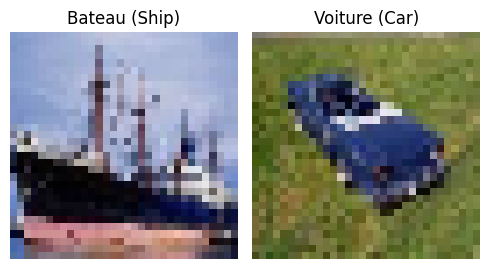

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def load_images_from_folder(folder, label, img_size=(32, 32)):
    images = []
    labels = []
    if not os.path.exists(folder):
        print(f" Dossier introuvable : {folder}")
        return images, labels

    for filename in os.listdir(folder):
        img_path = os.path.join(folder, filename)
        # Lecture de l'image
        img = cv2.imread(img_path)
        if img is not None:
            # Conversion de BGR (OpenCV) à RGB
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            # Redimensionnement uniforme
            img = cv2.resize(img, img_size)
            images.append(img)
            labels.append(label)
    return images, labels

# Dossiers pour chaque classe
ship_dir = os.path.join(DATA_DIR, "obj_ship")
car_dir = os.path.join(DATA_DIR, "obj_car")

# Chargement des images
ships_X, ships_y = load_images_from_folder(ship_dir, label=0)
cars_X, cars_y = load_images_from_folder(car_dir, label=1)

# Combinaison et normalisation dans [0, 1]
X = np.array(ships_X + cars_X, dtype="float32") / 255.0
y = np.array(ships_y + cars_y)

class_names = ["Bateau (Ship)", "Voiture (Car)"]

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Affichage des dimensions et des statistiques
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Répartition train:", np.bincount(y_train), "| test:", np.bincount(y_test))

# Aperçu des images
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
for c in range(2):
    idx = np.where(y_train == c)[0]
    if len(idx) > 0:
        ax[c].imshow(X_train[idx[0]])
        ax[c].set_title(class_names[c])
    ax[c].axis("off")
plt.tight_layout()
plt.show()

**Intérêt de la séparation apprentissage/test :** *(à rédiger avec vos mots : évaluer la généralisation sur des images jamais vues, détecter le surapprentissage.)*

## Étape B — Extraction des caractéristiques
RGB (moyenne/écart-type), histogramme HSV, GLCM, LBP, moments de Hu.

In [5]:
import time, warnings
import pandas as pd, seaborn as sns
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
warnings.filterwarnings("ignore")

def extract_features(img):
    img8 = (img * 255).astype(np.uint8)
    # 1) Statistiques RGB : moyenne et écart-type par canal (6)
    rgb = np.concatenate([img.mean(axis=(0, 1)), img.std(axis=(0, 1))])
    # 2) Histogramme HSV : 8 bins par canal (24)
    hsv = cv2.cvtColor(img8, cv2.COLOR_RGB2HSV)
    hist = np.concatenate([
        cv2.calcHist([hsv], [0], None, [8], [0, 180]).ravel(),
        cv2.calcHist([hsv], [1], None, [8], [0, 256]).ravel(),
        cv2.calcHist([hsv], [2], None, [8], [0, 256]).ravel()])
    hist = hist / (hist.sum() + 1e-8)
    gray = cv2.cvtColor(img8, cv2.COLOR_RGB2GRAY)
    # 3) GLCM : 5 propriétés x 4 angles (20)
    glcm = graycomatrix(gray // 8, distances=[1],
                        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    glcm_f = np.concatenate([graycoprops(glcm, p).ravel() for p in
             ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]])
    # 4) LBP uniforme (P=8, R=1) : histogramme de 10 bins (10)
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    lbp_h, _ = np.histogram(lbp, bins=np.arange(0, 11), density=True)
    # 5) Moments de Hu (7), échelle logarithmique
    hu = cv2.HuMoments(cv2.moments(gray)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)
    return np.concatenate([rgb, hist, glcm_f, lbp_h, hu])

t0 = time.time()
F_train = np.array([extract_features(i) for i in X_train])
F_test  = np.array([extract_features(i) for i in X_test])
print("F_train:", F_train.shape, "| F_test:", F_test.shape, f"| {time.time()-t0:.1f}s")
# une ligne = une image ; une colonne = une caractéristique (67 au total)

F_train: (392, 67) | F_test: (99, 67) | 0.9s


**Lecture de la matrice :** une ligne = une image, une colonne = une caractéristique (67 au total).

**Pourquoi des vecteurs de caractéristiques plutôt que les pixels bruts :** *(à rédiger avec vos mots.)*

## Étape C/E — Apprentissage avec GridSearchCV
**4 configurations SVM** (une par noyau : RBF, linéaire, sigmoïde, polynomial), chacune optimisée par grid search (validation croisée 3 plis sur l'ensemble d'apprentissage uniquement). La standardisation est dans le pipeline pour éviter toute fuite de données.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

# Même validation croisée pour tous les modèles (reproductible)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

svm_grids = {
    "SVM RBF":        {"svm__kernel": ["rbf"],     "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.001]},
    "SVM Linéaire":   {"svm__kernel": ["linear"],  "svm__C": [0.01, 0.1, 1, 10]},
    "SVM Sigmoïde":   {"svm__kernel": ["sigmoid"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.01, 0.001]},
    "SVM Polynomial": {"svm__kernel": ["poly"],    "svm__C": [0.1, 1, 10], "svm__degree": [2, 3]},
}

fitted, rows = {}, []

def evaluate(name, model, params, cv_mean, cv_std, fit_time):
    y_pred = model.predict(F_test)
    rows.append({
        "Modèle": name, "Paramètres": params,
        "Acc. CV (moy)": cv_mean, "Acc. CV (écart-type)": cv_std,
        "Accuracy (test)": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),   # positive = Voiture
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Temps (s)": fit_time})
    fitted[name] = model

# --- 4 configurations SVM (GridSearchCV) ---
for name, grid in svm_grids.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(random_state=RANDOM_STATE))])
    gs = GridSearchCV(pipe, grid, cv=skf, scoring="accuracy", n_jobs=-1)
    t0 = time.time(); gs.fit(F_train, y_train); dt = time.time() - t0
    best = {k.replace("svm__", ""): v for k, v in gs.best_params_.items()}
    std = gs.cv_results_["std_test_score"][gs.best_index_]
    evaluate(name, gs.best_estimator_, best, gs.best_score_, std, dt)
    print(f"{name}: {best} | CV={gs.best_score_:.4f} ± {std:.4f} | {dt:.1f}s")

# --- KNN (k=3, k=5) et arbre de décision ---
others = {
    "KNN (k=3)": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=3))]),
    "KNN (k=5)": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]),
    "Arbre de décision": DecisionTreeClassifier(random_state=RANDOM_STATE),
}
for name, m in others.items():
    sc = cross_val_score(m, F_train, y_train, cv=skf, scoring="accuracy")
    t0 = time.time(); m.fit(F_train, y_train); dt = time.time() - t0
    evaluate(name, m, "-", sc.mean(), sc.std(), dt)
    print(f"{name}: CV={sc.mean():.4f} ± {sc.std():.4f}")

SVM RBF: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'} | CV=0.9744 ± 0.0215 | 2.8s
SVM Linéaire: {'C': 0.1, 'kernel': 'linear'} | CV=0.9694 ± 0.0101 | 0.1s
SVM Sigmoïde: {'C': 1, 'gamma': 0.01, 'kernel': 'sigmoid'} | CV=0.9668 ± 0.0208 | 0.3s
SVM Polynomial: {'C': 10, 'degree': 2, 'kernel': 'poly'} | CV=0.9592 ± 0.0188 | 0.3s
KNN (k=3): CV=0.9667 ± 0.0310
KNN (k=5): CV=0.9667 ± 0.0238
Arbre de décision: CV=0.8979 ± 0.0217


## Étape C2 — Prédiction sur une image de test

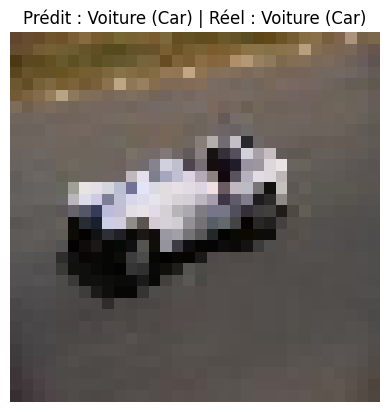

Meilleur modèle : KNN (k=3) | classe positive = Voiture


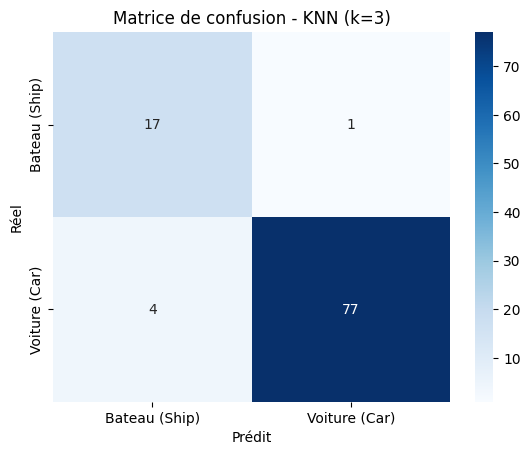

               precision    recall  f1-score   support

Bateau (Ship)     0.8095    0.9444    0.8718        18
Voiture (Car)     0.9872    0.9506    0.9686        81

     accuracy                         0.9495        99
    macro avg     0.8984    0.9475    0.9202        99
 weighted avg     0.9549    0.9495    0.9510        99



In [7]:
# Prédiction sur une image de test (SVM RBF)
idx = 0
pred = fitted["SVM RBF"].predict(F_test[idx:idx+1])[0]
plt.imshow(X_test[idx]); plt.axis("off")
plt.title(f"Prédit : {class_names[pred]} | Réel : {class_names[y_test[idx]]}")
plt.show()

# Évaluation détaillée du meilleur modèle
res = pd.DataFrame(rows)
best_name = res.loc[res["Accuracy (test)"].idxmax(), "Modèle"]
y_pred = fitted[best_name].predict(F_test)
print("Meilleur modèle :", best_name, "| classe positive = Voiture")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title(f"Matrice de confusion - {best_name}"); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

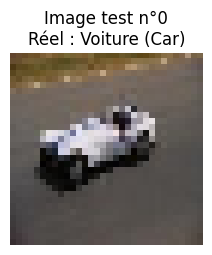

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Voiture (Car),Voiture (Car),✅
1,SVM Linéaire,Voiture (Car),Voiture (Car),✅
2,SVM Sigmoïde,Voiture (Car),Voiture (Car),✅
3,SVM Polynomial,Voiture (Car),Voiture (Car),✅
4,KNN (k=3),Voiture (Car),Voiture (Car),✅
5,KNN (k=5),Voiture (Car),Voiture (Car),✅
6,Arbre de décision,Voiture (Car),Voiture (Car),✅


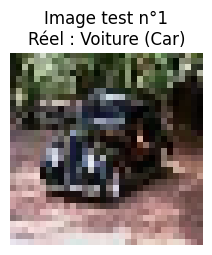

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Voiture (Car),Voiture (Car),✅
1,SVM Linéaire,Voiture (Car),Voiture (Car),✅
2,SVM Sigmoïde,Voiture (Car),Voiture (Car),✅
3,SVM Polynomial,Voiture (Car),Voiture (Car),✅
4,KNN (k=3),Voiture (Car),Voiture (Car),✅
5,KNN (k=5),Voiture (Car),Voiture (Car),✅
6,Arbre de décision,Voiture (Car),Voiture (Car),✅


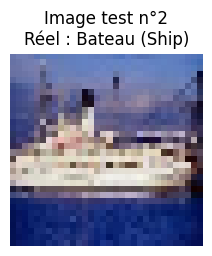

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Bateau (Ship),Bateau (Ship),✅
1,SVM Linéaire,Bateau (Ship),Bateau (Ship),✅
2,SVM Sigmoïde,Bateau (Ship),Bateau (Ship),✅
3,SVM Polynomial,Bateau (Ship),Bateau (Ship),✅
4,KNN (k=3),Bateau (Ship),Bateau (Ship),✅
5,KNN (k=5),Bateau (Ship),Bateau (Ship),✅
6,Arbre de décision,Bateau (Ship),Bateau (Ship),✅


Meilleur modèle : KNN (k=3) | classe positive = Voiture


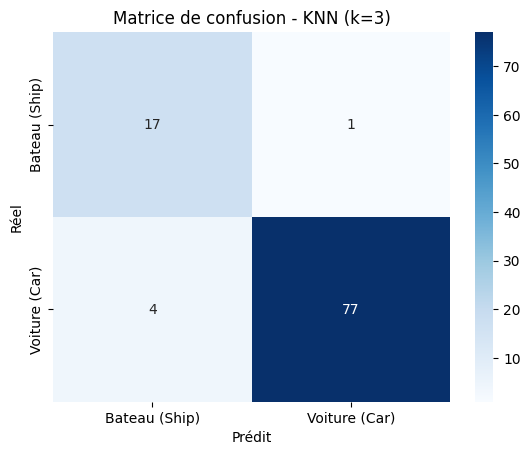

               precision    recall  f1-score   support

Bateau (Ship)     0.8095    0.9444    0.8718        18
Voiture (Car)     0.9872    0.9506    0.9686        81

     accuracy                         0.9495        99
    macro avg     0.8984    0.9475    0.9202        99
 weighted avg     0.9549    0.9495    0.9510        99



In [8]:
# --- Prédiction de TOUS les modèles sur quelques images de test ---
indices = [0, 1, 2]   # change ces indices pour tester d'autres images

for idx in indices:
    vraie = class_names[y_test[idx]]

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(X_test[idx]); plt.axis("off")
    plt.title(f"Image test n°{idx}\nRéel : {vraie}")
    plt.show()

    lignes = []
    for name, model in fitted.items():
        p = model.predict(F_test[idx:idx+1])[0]
        lignes.append({"Modèle": name,
                       "Prédiction": class_names[p],
                       "Étiquette réelle": vraie,
                       "Correct": "✅" if p == y_test[idx] else "❌"})
    display(pd.DataFrame(lignes))

# --- Évaluation détaillée du meilleur modèle ---
res = pd.DataFrame(rows)
best_name = res.loc[res["Accuracy (test)"].idxmax(), "Modèle"]
y_pred = fitted[best_name].predict(F_test)
print("Meilleur modèle :", best_name, "| classe positive = Voiture")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title(f"Matrice de confusion - {best_name}"); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

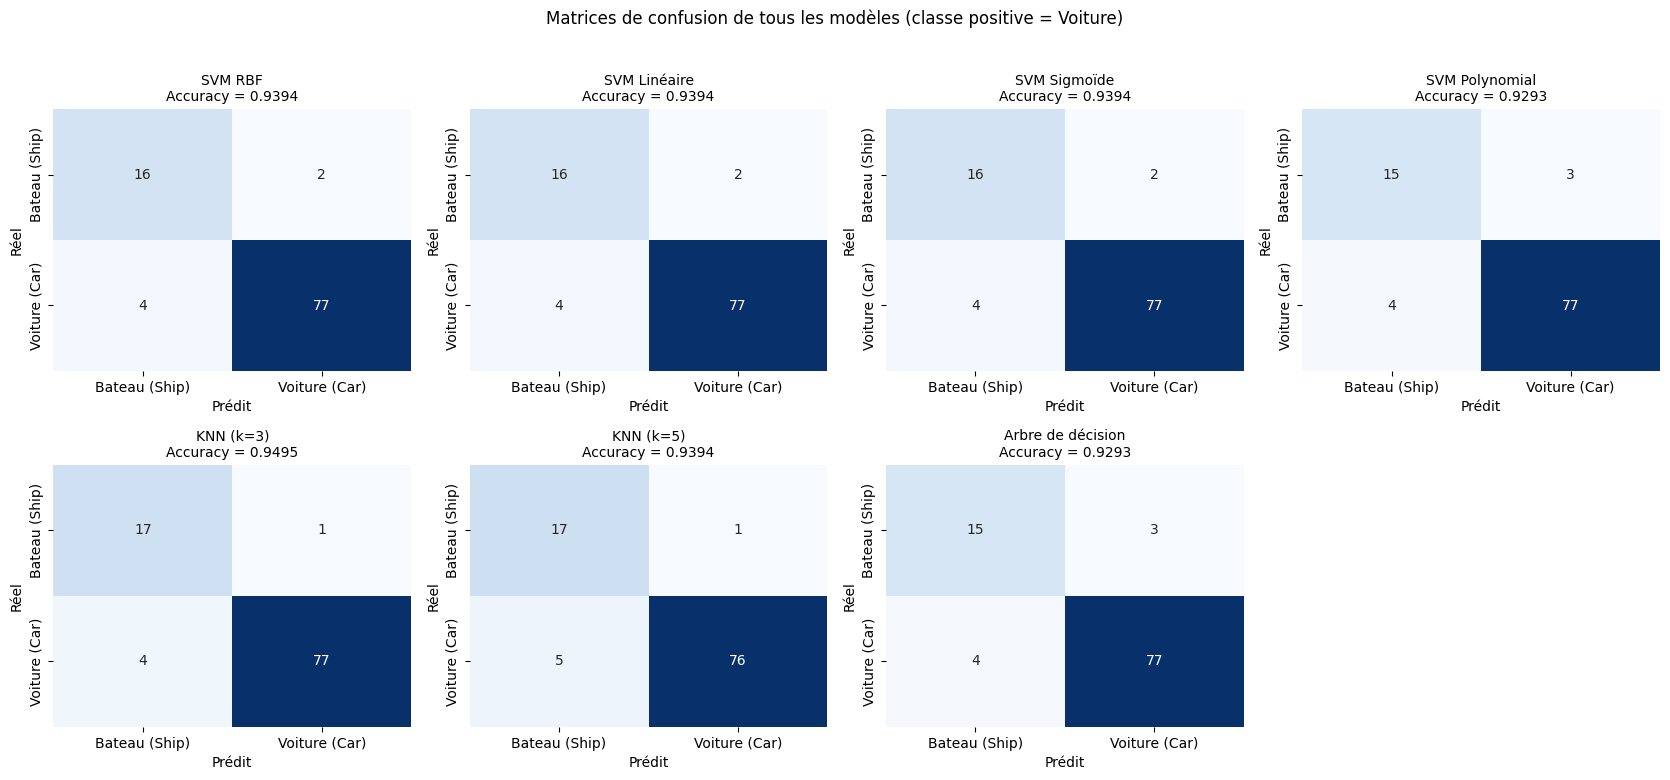

SVM RBF
               precision    recall  f1-score   support

Bateau (Ship)     0.8000    0.8889    0.8421        18
Voiture (Car)     0.9747    0.9506    0.9625        81

     accuracy                         0.9394        99
    macro avg     0.8873    0.9198    0.9023        99
 weighted avg     0.9429    0.9394    0.9406        99

SVM Linéaire
               precision    recall  f1-score   support

Bateau (Ship)     0.8000    0.8889    0.8421        18
Voiture (Car)     0.9747    0.9506    0.9625        81

     accuracy                         0.9394        99
    macro avg     0.8873    0.9198    0.9023        99
 weighted avg     0.9429    0.9394    0.9406        99

SVM Sigmoïde
               precision    recall  f1-score   support

Bateau (Ship)     0.8000    0.8889    0.8421        18
Voiture (Car)     0.9747    0.9506    0.9625        81

     accuracy                         0.9394        99
    macro avg     0.8873    0.9198    0.9023        99
 weighted avg     0.942

In [9]:
import math

noms = list(fitted.keys())
n_cols = 4
n_rows = math.ceil(len(noms) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.8 * n_rows))
axes = np.array(axes).ravel()

for ax, name in zip(axes, noms):
    y_pred_m = fitted[name].predict(F_test)
    cm = confusion_matrix(y_test, y_pred_m)
    acc = accuracy_score(y_test, y_pred_m)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {acc:.4f}", fontsize=10)
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")

# Masquer les cases vides de la grille
for ax in axes[len(noms):]:
    ax.axis("off")

plt.suptitle("Matrices de confusion de tous les modèles (classe positive = Voiture)", y=1.02)
plt.tight_layout()
plt.show()

# Rapport de classification de chaque modèle
for name in noms:
    print("=" * 60)
    print(name)
    print(classification_report(y_test, fitted[name].predict(F_test),
                                target_names=class_names, digits=4))

Interprétation : (VP, VN, FP, FN ; une bonne accuracy ne garantit pas que les deux classes sont bien reconnues : comparer precision/recall par classe.)

## Tableau comparatif final

,Modèle,Paramètres,Acc. CV (moy),Acc. CV (écart-type),Accuracy (test),Precision,Recall,F1-score,Temps (s)
1,KNN (k=3),-,0.966699,0.031004,0.9495,0.9872,0.9506,0.9686,0.0
2,SVM Linéaire,"{'C': 0.1, 'kernel': 'linear'}",0.969426,0.010112,0.9394,0.9747,0.9506,0.9625,0.1
3,SVM RBF,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.974424,0.021453,0.9394,0.9747,0.9506,0.9625,2.8
4,SVM Sigmoïde,"{'C': 1, 'gamma': 0.01, 'kernel': 'sigmoid'}",0.966829,0.020832,0.9394,0.9747,0.9506,0.9625,0.3
5,KNN (k=5),-,0.966732,0.023835,0.9394,0.9870,0.9383,0.9620,0.0
6,SVM Polynomial,"{'C': 10, 'degree': 2, 'kernel': 'poly'}",0.959169,0.018826,0.9293,0.9625,0.9506,0.9565,0.3
7,Arbre de décision,-,0.897858,0.021749,0.9293,0.9625,0.9506,0.9565,0.0


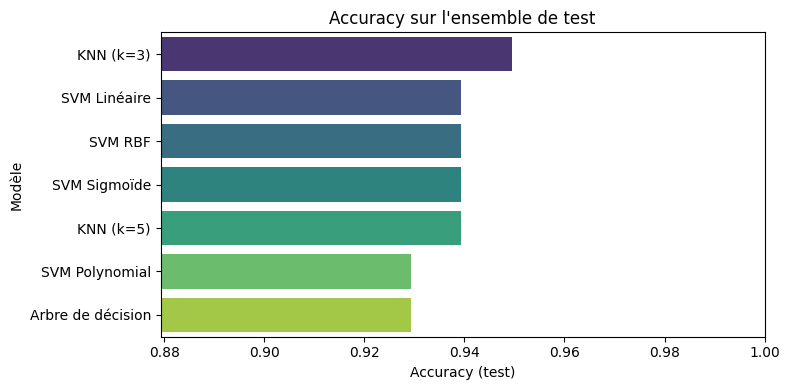

In [10]:
res = pd.DataFrame(rows).sort_values("Accuracy (test)", ascending=False).reset_index(drop=True)
res.index += 1
display(res.style.format({"Acc. CV (train)": "{:.4f}", "Accuracy (test)": "{:.4f}", "Precision": "{:.4f}",
                          "Recall": "{:.4f}", "F1-score": "{:.4f}", "Temps (s)": "{:.1f}"}, na_rep="-")
        .background_gradient(subset=["Accuracy (test)"], cmap="Greens"))

res.to_csv("/content/drive/MyDrive/comparaison_modeles.csv", index=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=res, y="Modèle", x="Accuracy (test)", palette="viridis")
plt.xlim(res["Accuracy (test)"].min() - 0.05, 1); plt.title("Accuracy sur l'ensemble de test"); plt.tight_layout(); plt.show()

In [11]:
print("rows existe :", "rows" in globals())
print("fitted existe :", "fitted" in globals())
print("class_names existe :", "class_names" in globals())

rows existe : True
fitted existe : True
class_names existe : True


In [12]:
import pandas as pd
import joblib
import os

# Sélectionner le meilleur modèle selon l'accuracy de test
res = pd.DataFrame(rows)

best_name = res.loc[
    res["Accuracy (test)"].idxmax(),
    "Modèle"
]

best_model = fitted[best_name]

# Sauvegarder le modèle
joblib.dump(
    {
        "model": best_model,
        "model_name": best_name,
        "class_names": class_names
    },
    "/content/modele_classification.pkl"
)

print("Modèle sélectionné :", best_name)
print("Modèle sauvegardé avec succès !")

Modèle sélectionné : KNN (k=3)
Modèle sauvegardé avec succès !


# **Conclusion**

Dans cet atelier, nous avons comparé 7 modèles pour classer des images de bateaux et de voitures à partir de caractéristiques extraites (couleur, texture, forme) : 4 configurations SVM optimisées par GridSearchCV, KNN (k=3 et k=5) et un arbre de décision.

Dans notre exécution, KNN (k=3) obtient la meilleure accuracy sur le test (0.9495), tandis que le SVM polynomial et l’arbre de décision sont les moins performants (0.9293). Les autres modèles sont très proches (0.9394). L’écart entre les modèles est faible, de l’ordre d’une image du jeu de test, donc il n’est pas forcément significatif. En validation croisée, le SVM RBF a la meilleure moyenne (0.9744), et l’arbre de décision est nettement plus faible (0.8979), ce qui suggère un surapprentissage.

Le choix de l’algorithme influence donc les résultats, mais ici la qualité des caractéristiques extraites compte autant que le modèle choisi. Une bonne accuracy ne garantit pas que les deux classes soient bien reconnues : il faut aussi analyser la precision, le recall et les matrices de confusion.

In [15]:
import joblib
import os

chemin = "/content/modele_classification.pkl"

print("Le fichier existe :", os.path.exists(chemin))

if os.path.exists(chemin):
    print("Taille du fichier :", os.path.getsize(chemin), "octets")

    try:
        modele = joblib.load(chemin)

        print("Modèle chargé avec succès !")
        print("Type du contenu :", type(modele))

        if isinstance(modele, dict):
            print("Clés disponibles :", modele.keys())

    except Exception as e:
        print("Erreur pendant le chargement :", repr(e))

Le fichier existe : True
Taille du fichier : 216202 octets
Modèle chargé avec succès !
Type du contenu : <class 'dict'>
Clés disponibles : dict_keys(['model', 'model_name', 'class_names'])


In [16]:
import os
import binascii

chemin = "/content/modele_classification.pkl"

with open(chemin, "rb") as f:
    debut = f.read(32)

print("Taille :", os.path.getsize(chemin), "octets")
print("Premiers octets :", binascii.hexlify(debut).decode())
print("En-tête lisible :", repr(debut))

Taille : 216202 octets
Premiers octets : 800495f2010000000000007d94288c056d6f64656c948c10736b6c6561726e2e
En-tête lisible : b'\x80\x04\x95\xf2\x01\x00\x00\x00\x00\x00\x00}\x94(\x8c\x05model\x94\x8c\x10sklearn.'


In [17]:

import joblib

chemin = "/content/modele_classification.pkl"

try:
    modele = joblib.load(chemin)
    print("Chargement réussi !")
    print("Type :", type(modele))

    if isinstance(modele, dict):
        print("Clés :", list(modele.keys()))

        for cle, valeur in modele.items():
            print(f"{cle} : {type(valeur)}")
except Exception as e:
    print("Erreur :", repr(e))


Chargement réussi !
Type : <class 'dict'>
Clés : ['model', 'model_name', 'class_names']
model : <class 'sklearn.pipeline.Pipeline'>
model_name : <class 'str'>
class_names : <class 'list'>


In [18]:
print("Nom du modèle :", modele["model_name"])
print("Classes :", modele["class_names"])
print("Étapes du pipeline :", modele["model"].named_steps)

Nom du modèle : KNN (k=3)
Classes : ['Bateau (Ship)', 'Voiture (Car)']
Étapes du pipeline : {'scaler': StandardScaler(), 'knn': KNeighborsClassifier(n_neighbors=3)}


In [19]:
from google.colab import files

files.download("/content/modele_classification.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import sklearn
import numpy
import cv2
import skimage
import joblib

print("scikit-learn :", sklearn.__version__)
print("numpy :", numpy.__version__)
print("opencv :", cv2.__version__)
print("scikit-image :", skimage.__version__)
print("joblib :", joblib.__version__)

scikit-learn : 1.6.1
numpy : 2.1.3
opencv : 4.14.0
scikit-image : 0.25.2
joblib : 1.6.0
